# Evolución de los precios de gasolina 95 y diésel
**Álvaro Quero Sandoval · Proyecto académico revisado · Python y análisis exploratorio**

Este trabajo estudia el archivo `gasolina.csv`, descrito en la entrega original como precios de
combustibles en España. Analiza la evolución de los valores registrados, sus diferencias y la
calidad de la serie. No realiza predicciones ni identifica causas económicas.

> **Alcance de los datos.** No se ha podido recuperar la fuente original. La representatividad
> nacional, la unidad exacta, el tratamiento de impuestos y descuentos y la convención semanal
> están pendientes de verificar. Las etiquetas en euros siguen la descripción original, pero
> no se da por confirmado que los valores sean medias nacionales en €/litro.

## Preguntas
1. ¿Qué cobertura, huecos y valores ausentes presenta el archivo?
2. ¿Cómo evolucionan los dos precios y dónde aparecen sus máximos observados?
3. ¿Cuándo supera el diésel a la gasolina en las observaciones disponibles?
4. ¿Qué resultados pueden describirse y cuáles requieren más información?

## Ejecución
Ejecutar todas las celdas en orden, con este directorio como carpeta de trabajo.
El CSV original no se modifica. Las tablas y figuras se guardan en `resultados/`.


In [1]:
from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display, Markdown

DATA_PATH = Path('gasolina.csv')
OUTPUT = Path('resultados')
OUTPUT.mkdir(exist_ok=True)
GAS = 'Precio de la gasolina 95'
DIESEL = 'Precio del diésel'
PRICES = [GAS, DIESEL]
COLORS = {GAS: '#2166ac', DIESEL: '#b35806'}
LABELS = {GAS: 'Gasolina 95', DIESEL: 'Diésel'}
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
environment = {'python': platform.python_version(), **{
    name: importlib.metadata.version(name)
    for name in ['pandas', 'numpy', 'matplotlib', 'plotly']
}}
display(environment)


{'python': '3.14.7',
 'pandas': '3.0.6',
 'numpy': '2.5.4',
 'matplotlib': '3.11.2',
 'plotly': '7.1.0'}

## 1. Carga y validación
Se conservan los campos de origen como texto antes de convertirlos. Una entrada no numérica
inesperada detiene la ejecución, en lugar de convertirse silenciosamente en un dato ausente.
Se comprueban columnas, año, formato de semana, duplicados, precios positivos y valores finitos.


In [2]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', dtype='string')
expected = ['Año', 'Periodo', GAS, DIESEL]
if list(raw.columns) != expected:
    raise ValueError(f'Columnas inesperadas: {list(raw.columns)}')
data = raw.copy()
years = pd.to_numeric(raw['Año'], errors='raise')
if years.isna().any() or (years % 1 != 0).any():
    raise ValueError('El año debe ser un entero no nulo.')
data['Año'] = years.astype(int)
week_text = raw['Periodo'].str.extract(r'^Semana ([1-9]|[1-4][0-9]|5[0-3])$', expand=False)
if week_text.isna().any():
    raise ValueError('Periodo debe tener el formato Semana N, con N entre 1 y 53.')
data['Semana'] = week_text.astype(int)
for column in PRICES:
    cleaned = raw[column].str.strip().replace('', pd.NA).str.replace(',', '.', regex=False)
    data[column] = pd.to_numeric(cleaned, errors='raise').astype(float)
    observed = data[column].dropna()
    if observed.empty or not np.isfinite(observed).all() or (observed <= 0).any():
        raise ValueError(f'Precios vacíos, no finitos o no positivos en {column}.')
if data.duplicated(['Año', 'Semana']).any():
    raise ValueError('Hay registros duplicados por año y semana: revisar antes de agregar.')
data = data.sort_values(['Año', 'Semana']).reset_index(drop=True)
display(data.head())
display(pd.DataFrame({'Tipo preparado': data.dtypes.astype(str), 'Ausentes': data.isna().sum()}))
print(f'{len(data):,} registros. CSV SHA-256: {hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}')


,Año,Periodo,Precio de la gasolina 95,Precio del diésel,Semana
0,2002,Semana 2,0.76,0.67,2
1,2002,Semana 3,0.77,0.67,3
2,2002,Semana 4,0.76,0.67,4
3,2002,Semana 5,0.76,0.67,5
4,2002,Semana 6,0.77,0.67,6


,Tipo preparado,Ausentes
Año,int64,0
Periodo,string,0
Precio de la gasolina 95,float64,0
Precio del diésel,float64,1
Semana,int64,0


1,134 registros. CSV SHA-256: 402b844a57f272a1096019b6f3ea01d5620ec8de955787b064b7a1cccadded86


## 2. Cobertura y datos ausentes
No se imputa el precio ausente: su valor real se desconoce. Los estadísticos de cada combustible
usan sus observaciones disponibles y la diferencia entre combustibles usa solo pares completos.

La tabla compara los registros con las etiquetas 1–52 para detectar diferencias de cobertura.
Esto **no supone que exista una observación obligatoria cada semana**. La fuente podría omitir
semanas por su calendario de publicación. La semana 53 de 2022 se conserva: no se interpreta
automáticamente como una fecha ISO. En 2024 solo hay datos hasta la semana 44.


In [3]:
coverage_rows = []
for year, group in data.groupby('Año'):
    weeks = set(group['Semana'])
    coverage_rows.append({
        'Año': year, 'Registros': len(group), 'Primera semana': min(weeks),
        'Última semana': max(weeks), 'Gasolina válida': group[GAS].count(),
        'Diésel válido': group[DIESEL].count(),
        'Etiquetas ausentes de 1 a 52': ', '.join(map(str, sorted(set(range(1, 53)) - weeks))),
        'Tiene semana 53': 53 in weeks
    })
coverage = pd.DataFrame(coverage_rows)
missing = data.loc[data[PRICES].isna().any(axis=1)]
display(coverage)
display(Markdown('**Registros con algún precio ausente:**'))
display(missing)
coverage.to_csv(OUTPUT / 'cobertura.csv', index=False, encoding='utf-8-sig')


,Año,Registros,Primera semana,Última semana,Gasolina válida,Diésel válido,Etiquetas ausentes de 1 a 52,Tiene semana 53
0,2002,49,2,51,49,49,"1, 14, 52",False
1,2003,48,2,51,48,48,"1, 17, 33, 52",False
2,2004,51,2,52,51,51,1,False
3,2005,49,2,52,49,49,"1, 14, 45",False
4,2006,49,3,52,49,49,"1, 2, 17",False
5,2007,49,2,51,49,49,"1, 15, 52",False
6,2008,49,2,51,49,49,"1, 13, 52",False
7,2009,50,2,52,50,50,"1, 16",False
8,2010,49,2,52,49,49,"1, 15, 45",False
9,2011,49,2,52,49,49,"1, 18, 34",False


**Registros con algún precio ausente:**

,Año,Periodo,Precio de la gasolina 95,Precio del diésel,Semana
903,2020,Semana 17,1.11,NaN,17


## 3. Resumen descriptivo y revisión de extremos
Los resúmenes agrupan niveles de precios de años diferentes. Son descripciones del archivo,
no estimaciones del precio actual. Los máximos y mínimos no se eliminan por ser extremos:
sin la fuente no puede decidirse que sean errores. Tampoco se ajustan los precios por inflación.


In [4]:
display(data[PRICES].describe().round(3))
extreme_rows = []
for column in PRICES:
    for kind, value in [('Mínimo', data[column].min()), ('Máximo', data[column].max())]:
        for _, row in data.loc[data[column].eq(value)].iterrows():
            extreme_rows.append({'Combustible': LABELS[column], 'Extremo': kind,
                                 'Año': int(row['Año']), 'Semana': int(row['Semana']), 'Precio': value})
extremes = pd.DataFrame(extreme_rows)
display(extremes)
annual = data.groupby('Año')[PRICES].agg(['count', 'mean', 'median', 'min', 'max'])
annual.columns = [f'{LABELS[fuel]} - {stat}' for fuel, stat in annual.columns]
display(annual.round(3))
annual.to_csv(OUTPUT / 'resumen_anual.csv', encoding='utf-8-sig')
extremes.to_csv(OUTPUT / 'extremos.csv', index=False, encoding='utf-8-sig')


,Precio de la gasolina 95,Precio del diésel
count,1134.000,1133.000
mean,1.224,1.139
std,0.257,0.275
min,0.760,0.660
25%,1.060,0.960
50%,1.210,1.130
75%,1.390,1.320
max,2.140,2.100


,Combustible,Extremo,Año,Semana,Precio
0,Gasolina 95,Mínimo,2002,2,0.76
1,Gasolina 95,Mínimo,2002,4,0.76
2,Gasolina 95,Mínimo,2002,5,0.76
3,Gasolina 95,Máximo,2022,26,2.14
4,Diésel,Mínimo,2003,24,0.66
5,Diésel,Mínimo,2003,25,0.66
6,Diésel,Mínimo,2003,26,0.66
7,Diésel,Mínimo,2003,27,0.66
8,Diésel,Mínimo,2003,39,0.66
9,Diésel,Mínimo,2003,40,0.66


,Gasolina 95 - count,Gasolina 95 - mean,Gasolina 95 - median,Gasolina 95 - min,Gasolina 95 - max,Diésel - count,Diésel - mean,Diésel - median,Diésel - min,Diésel - max
Año,,,,,,,,,,
2002,49,0.812,0.820,0.76,0.85,49,0.688,0.68,0.67,0.71
2003,48,0.818,0.815,0.79,0.87,48,0.696,0.68,0.66,0.77
2004,51,0.875,0.890,0.79,0.93,51,0.758,0.75,0.68,0.85
2005,49,0.962,0.960,0.84,1.10,49,0.899,0.91,0.81,0.98
2006,49,1.036,1.020,0.95,1.14,49,0.959,0.95,0.91,1.01
2007,49,1.050,1.070,0.94,1.11,49,0.968,0.97,0.88,1.08
2008,49,1.131,1.140,0.86,1.28,49,1.151,1.15,0.89,1.33
2009,50,1.006,1.035,0.83,1.10,50,0.914,0.93,0.83,0.98
2010,49,1.163,1.170,1.09,1.24,49,1.075,1.09,0.99,1.17


## 4. Evolución de toda la serie
El eje sigue el año y la semana declarados, sin inventar fechas. Se reservan posiciones para
las semanas sin registro dentro del intervalo observado y las líneas se interrumpen en ellas.
Los espacios entre semanas son uniformes y no equivalen a fechas de calendario verificadas.
Se muestran precios semanales observados, no máximos anuales.


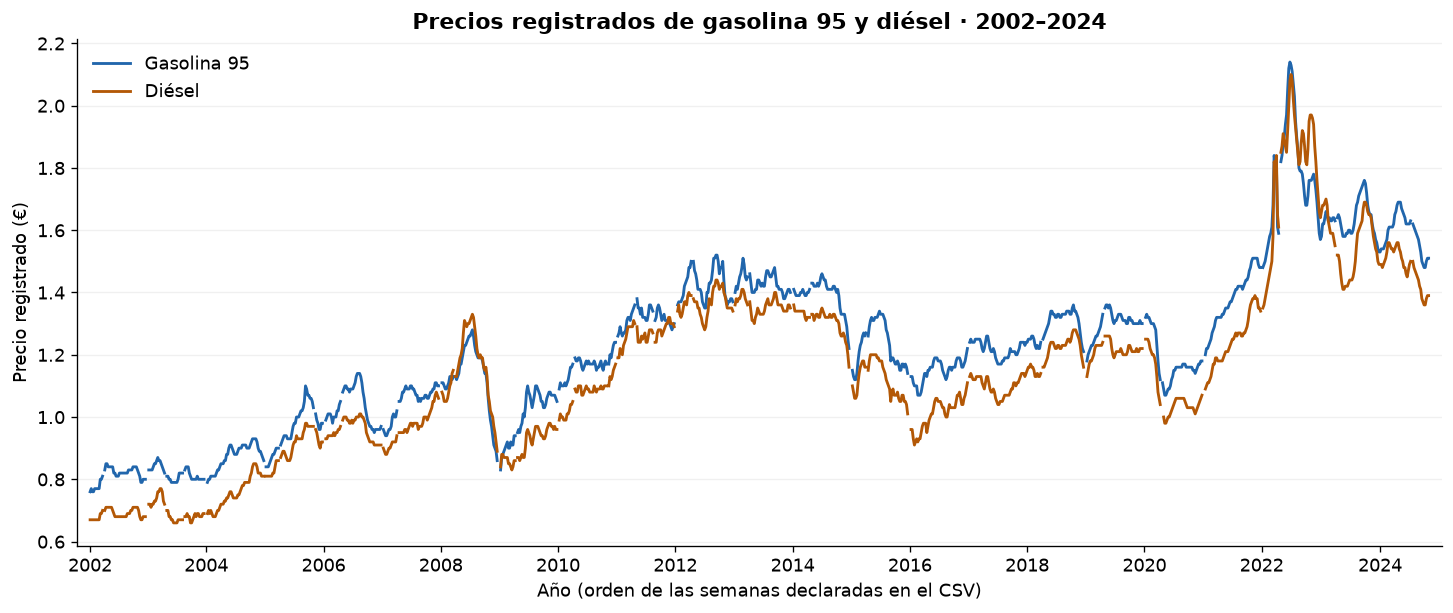

In [5]:
grid_keys = []
for year, group in data.groupby('Año'):
    start = int(group['Semana'].min()) if year == data['Año'].min() else 1
    end = int(group['Semana'].max()) if year == data['Año'].max() else max(52, int(group['Semana'].max()))
    grid_keys.extend((int(year), week) for week in range(start, end + 1))
grid = data.set_index(['Año', 'Semana'])[PRICES].reindex(
    pd.MultiIndex.from_tuples(grid_keys, names=['Año', 'Semana'])
).reset_index()
grid['Posición'] = np.arange(len(grid))
ticks = grid.groupby('Año')['Posición'].first()
tick_years = [year for year in ticks.index if year % 2 == 0]

def format_time_axis(ax):
    ax.set_xticks([ticks.loc[year] for year in tick_years], tick_years)
    ax.set_xlabel('Año (orden de las semanas declaradas en el CSV)')
    ax.grid(axis='y', alpha=0.18)
    ax.margins(x=0.01)

fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
for column in PRICES:
    ax.plot(grid['Posición'], grid[column], color=COLORS[column], label=LABELS[column], linewidth=1.7)
ax.set_title('Precios registrados de gasolina 95 y diésel · 2002–2024')
ax.set_ylabel('Precio registrado (€)')
format_time_axis(ax)
ax.legend(frameon=False)
fig.savefig(OUTPUT / 'evolucion.png', dpi=160)
plt.show()


## 5. Comparación entre combustibles
Una diferencia positiva significa que la gasolina supera al diésel. Una negativa significa
lo contrario. El porcentaje se calcula sobre pares de precios observados, no sobre todos
los días del período ni sobre el número de estaciones de servicio.


El diésel supera a la gasolina en **75 de 1133 pares** (6.6 %). La diferencia media gasolina − diésel es **0.085 €** en estos pares.

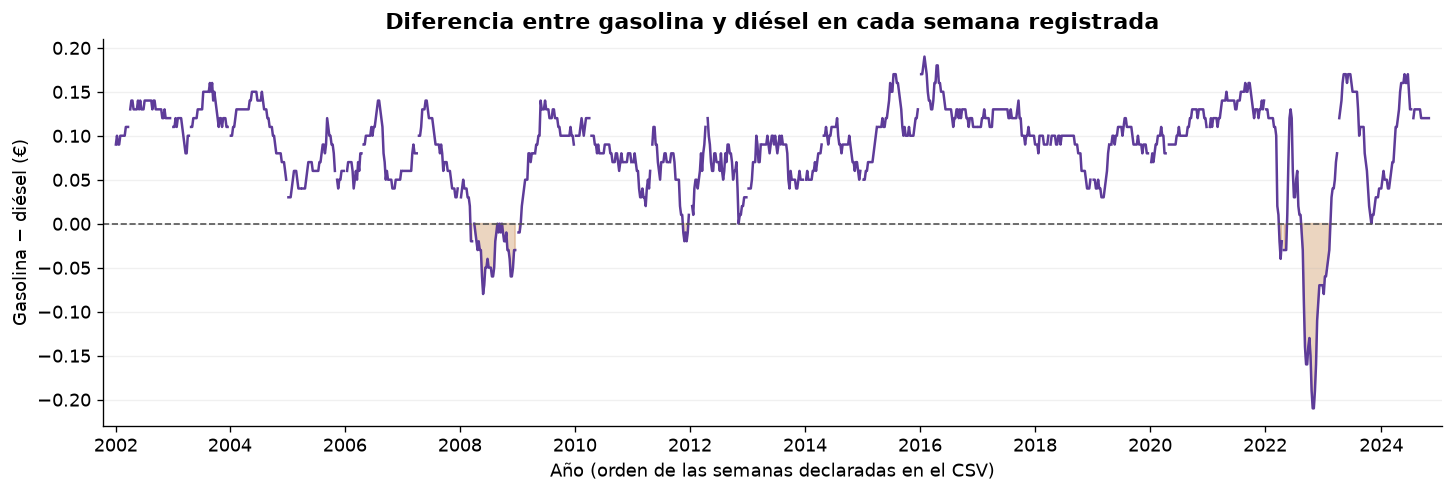

In [6]:
pairs = data.dropna(subset=PRICES).copy()
pairs['Diferencia gasolina menos diésel'] = pairs[GAS] - pairs[DIESEL]
diesel_higher = int((pairs[DIESEL] > pairs[GAS]).sum())
pct_diesel_higher = 100 * diesel_higher / len(pairs)
display(Markdown(f'El diésel supera a la gasolina en **{diesel_higher} de {len(pairs)} pares** '
                 f'({pct_diesel_higher:.1f} %). La diferencia media gasolina − diésel es '
                 f'**{pairs["Diferencia gasolina menos diésel"].mean():.3f} €** en estos pares.'))
spread = grid[GAS] - grid[DIESEL]
fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
ax.plot(grid['Posición'], spread, color='#5e3c99', linewidth=1.5)
ax.axhline(0, color='#555555', linewidth=1, linestyle='--')
ax.fill_between(grid['Posición'], spread, 0, where=spread < 0, color=COLORS[DIESEL], alpha=0.25)
ax.set_title('Diferencia entre gasolina y diésel en cada semana registrada')
ax.set_ylabel('Gasolina − diésel (€)')
format_time_axis(ax)
fig.savefig(OUTPUT / 'diferencia.png', dpi=160)
plt.show()
pairs.to_csv(OUTPUT / 'comparacion_pares.csv', index=False, encoding='utf-8-sig')


## 6. Distribución histórica
Ambos histogramas utilizan exactamente los mismos intervalos de precio. Mezclan todos los años
y no deben interpretarse como una distribución del precio actual ni como evidencia de estacionalidad.


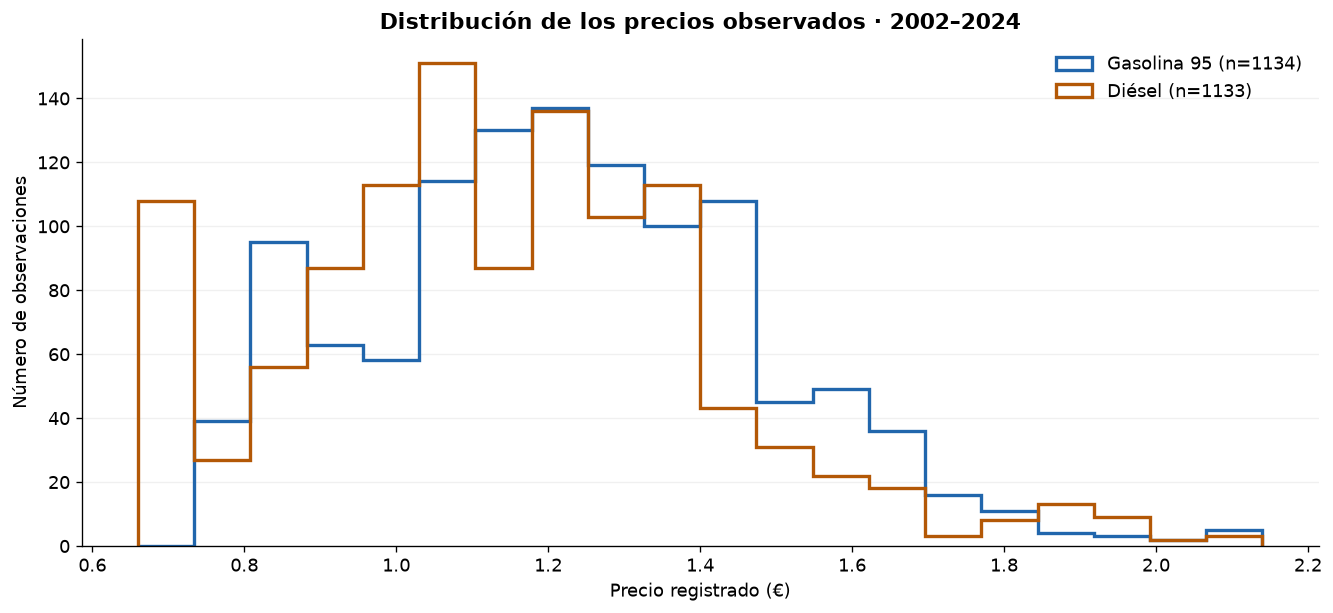

In [7]:
bins = np.linspace(data[PRICES].min().min(), data[PRICES].max().max(), 21)
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
for column in PRICES:
    values = data[column].dropna()
    ax.hist(values, bins=bins, histtype='step', linewidth=2, color=COLORS[column],
            label=f'{LABELS[column]} (n={len(values)})')
ax.set_title('Distribución de los precios observados · 2002–2024')
ax.set_xlabel('Precio registrado (€)')
ax.set_ylabel('Número de observaciones')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.18)
fig.savefig(OUTPUT / 'distribucion.png', dpi=160)
plt.show()


## 7. Detalle interactivo por año
El selector muestra el año, conserva los colores y usa la misma escala vertical para facilitar
la comparación. No une semanas sin precio. El archivo HTML exportado contiene Plotly y puede
abrirse sin conexión. La serie completa anterior es la referencia estática para lectores sin Plotly.


In [8]:
interactive = go.Figure()
years = sorted(data['Año'].unique())
for year in years:
    subset = grid.loc[grid['Año'].eq(year)]
    for column in PRICES:
        interactive.add_trace(go.Scatter(
            x=subset['Semana'].tolist(), y=subset[column].where(subset[column].notna(), None).tolist(),
            name=LABELS[column], mode='lines+markers', line={'color': COLORS[column]},
            marker={'size': 4}, connectgaps=False, visible=(year == years[0]),
            hovertemplate='Semana %{x}<br>Precio: %{y:.2f} €<extra>%{fullData.name}</extra>'
        ))
steps = []
for i, year in enumerate(years):
    visible = [False] * len(interactive.data)
    visible[2*i:2*i+2] = [True, True]
    steps.append({'label': str(year), 'method': 'update',
                  'args': [{'visible': visible}, {'title': {'text': f'Precios registrados en {year}'}}]})
interactive.update_layout(
    title=f'Precios registrados en {years[0]}', template='plotly_white',
    xaxis={'title': 'Semana declarada (calendario no verificado)', 'range': [1, 53]},
    yaxis={'title': 'Precio registrado (€)', 'range': [0.60, 2.25]},
    sliders=[{'active': 0, 'steps': steps, 'currentvalue': {'prefix': 'Año: '}}],
    margin={'b': 110}, height=520
)
interactive.write_html(OUTPUT / 'detalle_interactivo.html', include_plotlyjs=True, full_html=True)
display(Markdown('[Abrir el detalle interactivo](resultados/detalle_interactivo.html). '
                 'El fichero se ha exportado con 23 años y dos series por año.'))


[Abrir el detalle interactivo](resultados/detalle_interactivo.html). El fichero se ha exportado con 23 años y dos series por año.

## 8. Conclusiones calculadas
Los resultados siguientes se generan desde el CSV para evitar cifras escritas a mano que
queden desactualizadas al volver a ejecutar el análisis.


In [9]:
maxima = {}
for column in PRICES:
    row = data.loc[data[column].idxmax()]
    maxima[LABELS[column]] = {'precio': float(row[column]), 'año': int(row['Año']), 'semana': int(row['Semana'])}
summary = {
    'registros': len(data), 'pares_validos': len(pairs), 'precios_ausentes': int(data[PRICES].isna().sum().sum()),
    'diesel_supera_gasolina': diesel_higher, 'porcentaje_diesel_supera_gasolina': pct_diesel_higher,
    'diferencia_media_pares': float(pairs['Diferencia gasolina menos diésel'].mean()),
    'maximos': maxima, 'entorno': environment,
    'csv_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
}
lines = [f'- Se analizan **{len(data)} registros** entre 2002 y 2024; 2024 termina en la semana 44.',
         f'- Hay **{summary["precios_ausentes"]} precio ausente**, que se conserva sin imputar. No hay duplicados por año y semana.']
for fuel, values in maxima.items():
    lines.append(f'- El máximo observado de **{fuel}** es **{values["precio"]:.2f} €**, '
                 f'en {values["año"]}, semana {values["semana"]}.')
lines.append(f'- El diésel supera a la gasolina en **{diesel_higher}/{len(pairs)}** pares '
             f'(**{pct_diesel_higher:.1f} %**). Esto describe los registros disponibles.')
display(Markdown('\n'.join(lines)))
(OUTPUT / 'resumen.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')


- Se analizan **1134 registros** entre 2002 y 2024; 2024 termina en la semana 44.
- Hay **1 precio ausente**, que se conserva sin imputar. No hay duplicados por año y semana.
- El máximo observado de **Gasolina 95** es **2.14 €**, en 2022, semana 26.
- El máximo observado de **Diésel** es **2.10 €**, en 2022, semana 27.
- El diésel supera a la gasolina en **75/1133** pares (**6.6 %**). Esto describe los registros disponibles.

624

## Limitaciones y siguientes pasos
- **Procedencia pendiente:** recuperar la fuente, la fecha de descarga, las condiciones de reutilización
  y la definición exacta del precio antes de presentar estos resultados como estadísticas nacionales verificadas.
- **Calendario pendiente:** documentar la semana 53 de 2022 y el calendario de publicación. No inventar fechas.
- **Cobertura desigual:** las medias anuales usan cantidades distintas de observaciones y 2024 es parcial.
  Los huecos no se rellenan. Las comparaciones entre años deben tenerlo en cuenta.
- **Sin inferencia causal:** las variaciones observadas no prueban el efecto de guerras, pandemias u otros hitos.
- **Sin conclusión estacional:** promediar por número de semana mezclando años con distinta cobertura
  genera comparaciones no homogéneas. Por eso se ha retirado esa interpretación.
- **Precios sin ajuste por inflación:** no se comparan poder adquisitivo ni costes reales.

El siguiente paso útil es recuperar los metadatos y contrastar los valores con una fuente documentada.
No hace falta añadir un modelo predictivo para completar este EDA.
